# Aircast Phase 2: independent recurrent models and calibrated hybrid

This notebook inspects the measured experiment and runs saved-model inference. Set `RUN_FULL_RESEARCH=True` to repeat training into a fresh directory. Model selection uses 2013. The 2014 comparison is exploratory because its Phase 1 results were already known.


In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if not (ROOT / 'src/air_prediction').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/air_prediction').exists(), 'Open this notebook from the project checkout'
os.chdir(ROOT)
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(key, '1')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
sys.path.insert(0, str(ROOT / 'src'))
try:
    from IPython.display import display
except ImportError:
    display = print
print('Project:', ROOT)


Project: /Users/prathammalhotra/Desktop/air_pred


## Environment

Use Python 3.13 and `requirements-phase2.txt` to match the recorded models. On macOS, XGBoost also needs `brew install libomp`. Installation is opt-in below.


In [2]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', 'requirements-phase2.txt'])
import pandas as pd
from air_prediction.config import load_config
from air_prediction.phase2_research import load_research_settings, run_research
from air_prediction.predict import predict_latest
from air_prediction.data import load_dataset
CONFIG = load_config(ROOT / 'configs/phase1.toml')
SETTINGS = load_research_settings(ROOT / 'configs/phase2_research.toml')
DATA = ROOT / 'data/raw/PRSA_data_2010.1.1-2014.12.31.csv'
print(load_dataset(DATA).audit)


{'source': 'uci381_user_supplied', 'path': '/Users/prathammalhotra/Desktop/air_pred/data/raw/PRSA_data_2010.1.1-2014.12.31.csv', 'sha256': '4127f868775e31b3956522adc0ec75af8937dde6a3896e8beed3a376c6d27f1c', 'input_rows': 43824, 'hourly_rows': 43824, 'inserted_missing_hours': 0, 'input_was_sorted': True, 'duplicate_timestamps': 0, 'start': '2010-01-01 00:00:00', 'end': '2014-12-31 23:00:00', 'timezone': 'Asia/Shanghai (local clock)', 'missing_by_column': {'pm2.5': 2067, 'DEWP': 0, 'TEMP': 0, 'PRES': 0, 'Iws': 0, 'Is': 0, 'Ir': 0, 'cbwd': 0}, 'provenance': {'source': 'uci381_user_supplied', 'acquisition': 'User-provided local CSV; no download performed by this run', 'original_filename': 'PRSA_data_2010.1.1-2014.12.31.csv', 'dataset_page': 'https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data', 'doi': '10.24432/C5JS49', 'license': 'CC BY 4.0', 'sha256': '4127f868775e31b3956522adc0ec75af8937dde6a3896e8beed3a376c6d27f1c', 'verified': 'Expected columns and complete 2010–2014 hourly tim

## Reproduce the experiment

The full run trains eight screening candidates, paired attention/directionality variants at three seeds, and chronological hybrid candidates. Standalone neural models use every eligible training row. The hybrid base is frozen before its calibration block. Completed runs are never overwritten.


In [3]:
RUN_FULL_RESEARCH = False
RUN = ROOT / 'artifacts/phase2_research'
if RUN_FULL_RESEARCH:
    from datetime import datetime
    RUN = ROOT / 'artifacts' / ('phase2_notebook_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
    run_research(DATA, CONFIG, RUN, ROOT / 'artifacts/phase1', SETTINGS)
assert (RUN / 'run_manifest.json').exists(), 'Run training or extract the submission package with saved artifacts'
manifest = json.loads((RUN / 'run_manifest.json').read_text())
assert manifest['status'] == 'complete'
assert load_dataset(DATA).audit['sha256'] == manifest['dataset_audit']['sha256']
selection = json.loads((RUN / 'selection.json').read_text())
assert selection['holdout_used_for_selection'] is False
print('Run:', RUN)
print('Validation preference:', selection['preferred_model'])
print('Selected configurations:', selection['neural_configurations'])


Run: /Users/prathammalhotra/Desktop/air_pred/artifacts/phase2_research
Validation preference: lstm
Selected configurations: {'bilstm': {'seq_len': 24, 'hidden_dim': 32, 'num_layers': 1, 'dropout': 0.1, 'batch_size': 128, 'learning_rate': 0.001, 'epochs': 6, 'device': 'cpu', 'architecture': 'bilstm', 'random_seed': 42, 'use_attention': False, 'target_mode': 'delta'}, 'lstm': {'seq_len': 24, 'hidden_dim': 32, 'num_layers': 1, 'dropout': 0.1, 'batch_size': 128, 'learning_rate': 0.001, 'epochs': 6, 'device': 'cpu', 'architecture': 'lstm', 'random_seed': 42, 'use_attention': False, 'target_mode': 'delta'}}


## Verify evidence and inspect scores

Every model uses identical target hours; the deployment fits are separate from the fits used for scoring.


In [4]:
from hashlib import sha256
from air_prediction.metrics import score_predictions
assert sha256((RUN / 'selection.json').read_bytes()).hexdigest() == manifest['selection_sha256']
for name, expected in manifest['model_sha256'].items():
    assert sha256((RUN / (name + '.joblib')).read_bytes()).hexdigest() == expected
predictions = pd.read_csv(RUN / 'predictions.csv', parse_dates=['origin_time', 'target_time'], low_memory=False)
metrics = pd.read_csv(RUN / 'metrics.csv')
pd.testing.assert_frame_equal(score_predictions(predictions), metrics, check_exact=False, rtol=1e-10)
display(metrics)


         phase           model     n        mae        rmse        r2      bias
0      holdout          bilstm  8531  11.456603   20.799313  0.950294  0.831190
1      holdout          hybrid  8531  11.482988   20.918685  0.949722  0.322038
2      holdout            lstm  8531  11.298725   20.725919  0.950645  0.807610
3      holdout     persistence  8531  11.926386   22.033489  0.944221  0.009612
4      holdout           ridge  8531  11.825318   21.062610  0.949028  0.218345
5      holdout  seasonal_naive  8531  67.295745   98.754410 -0.120523  0.239831
6      holdout         xgboost  8531  11.832610   21.087813  0.948906  0.719481
7   validation          bilstm  8563  12.816986   23.596030  0.942198 -0.860614
8   validation          hybrid  8563  12.792179   23.546958  0.942438 -0.278786
9   validation            lstm  8563  12.684408   23.462117  0.942852 -0.492660
10  validation     persistence  8563  13.183697   24.869582  0.935790  0.032232
11  validation           ridge  8563  13

In [5]:
for name in ('search_metrics.csv', 'ablation_metrics.csv', 'seed_stability.csv', 'errors_by_pollution_regime.csv'):
    print('\n' + name)
    display(pd.read_csv(RUN / name))



search_metrics.csv
                   candidate  rmse_mean  ...  seeds  hours_per_seed
0     delta_24h_no_attention  23.596030  ...      1            8563
1     delta_48h_no_attention  23.620686  ...      1            8563
2  delta_24h_longer_training  23.897097  ...      1            8563
3            level_24h_wider  25.171571  ...      1            8563
4        level_48h_attention  25.576460  ...      1            8563
5        level_24h_attention  25.791768  ...      1            8563
6     level_24h_no_attention  25.799435  ...      1            8563
7  level_24h_longer_training  25.819026  ...      1            8563

[8 rows x 7 columns]

ablation_metrics.csv
             candidate  rmse_mean  rmse_std  ...   mae_std  seeds  hours_per_seed
0    lstm_no_attention  23.501534  0.131125  ...  0.082030      3            8563
1  bilstm_no_attention  23.613076  0.132197  ...  0.081806      3            8563
2     bilstm_attention  23.703200  0.061986  ...  0.083811      3            8

## Figures

Seed error bars describe variation across predefined seeds and are not confidence intervals.


/Users/prathammalhotra/Desktop/air_pred/docs/results/phase2_research/model_comparison.png
/Users/prathammalhotra/Desktop/air_pred/docs/results/phase2_research/attention_ablation.png
/Users/prathammalhotra/Desktop/air_pred/docs/results/phase2_research/pollution_regimes.png


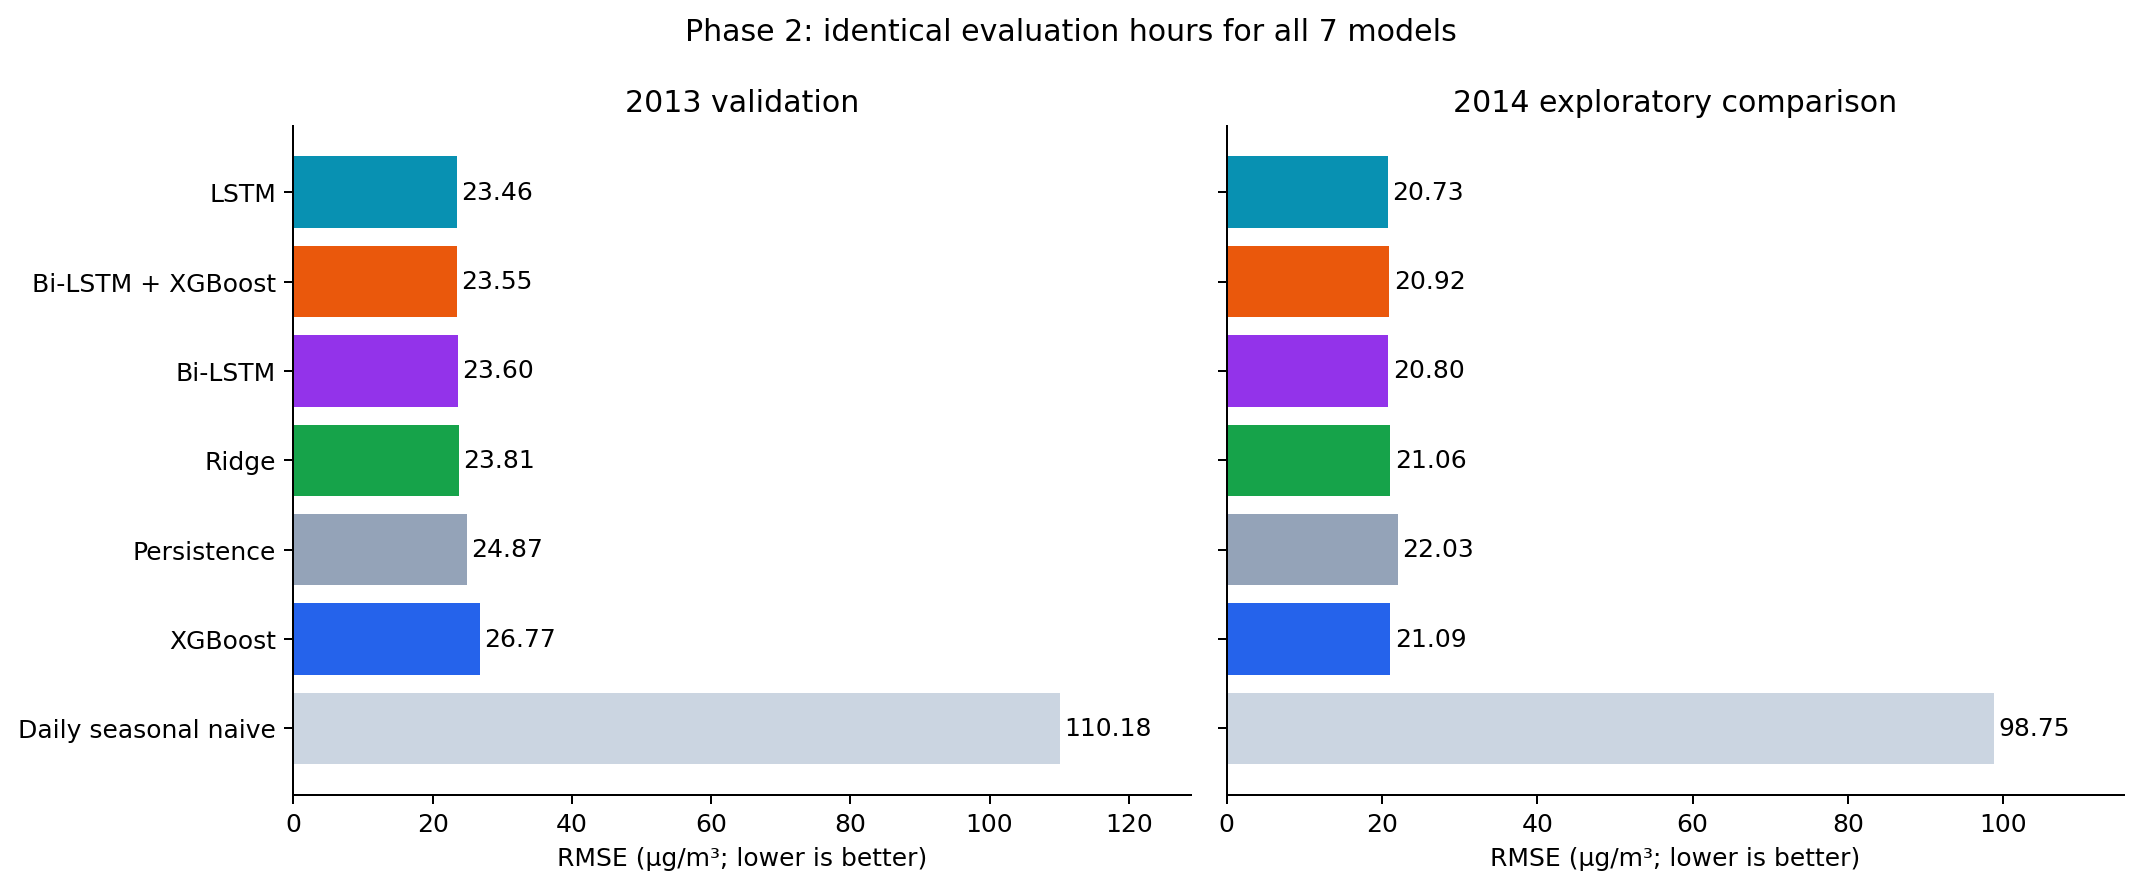

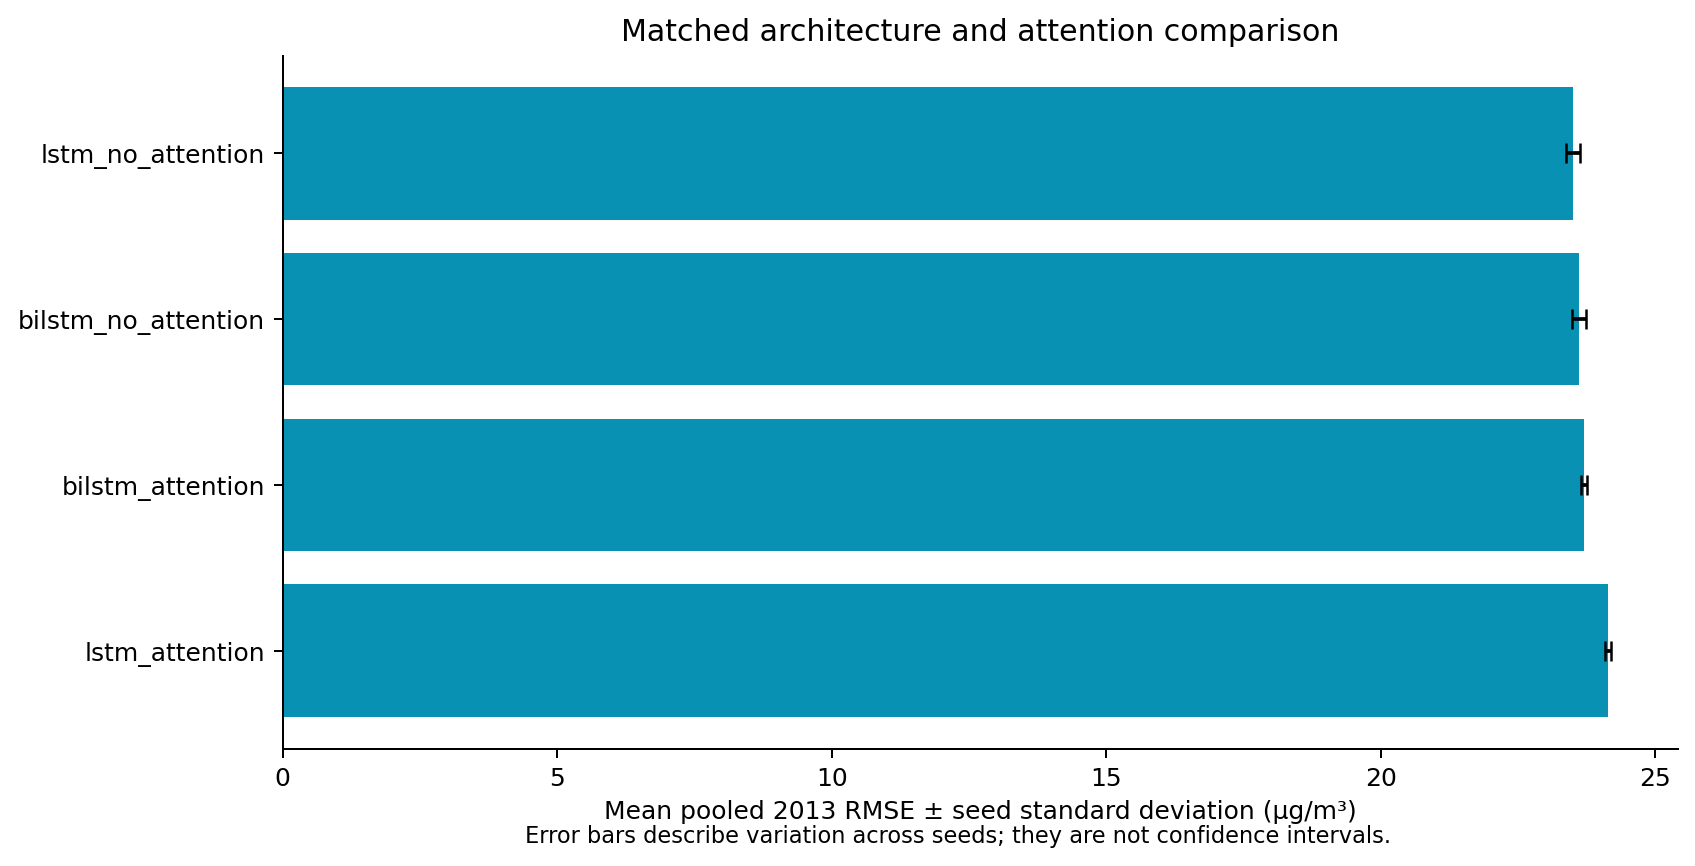

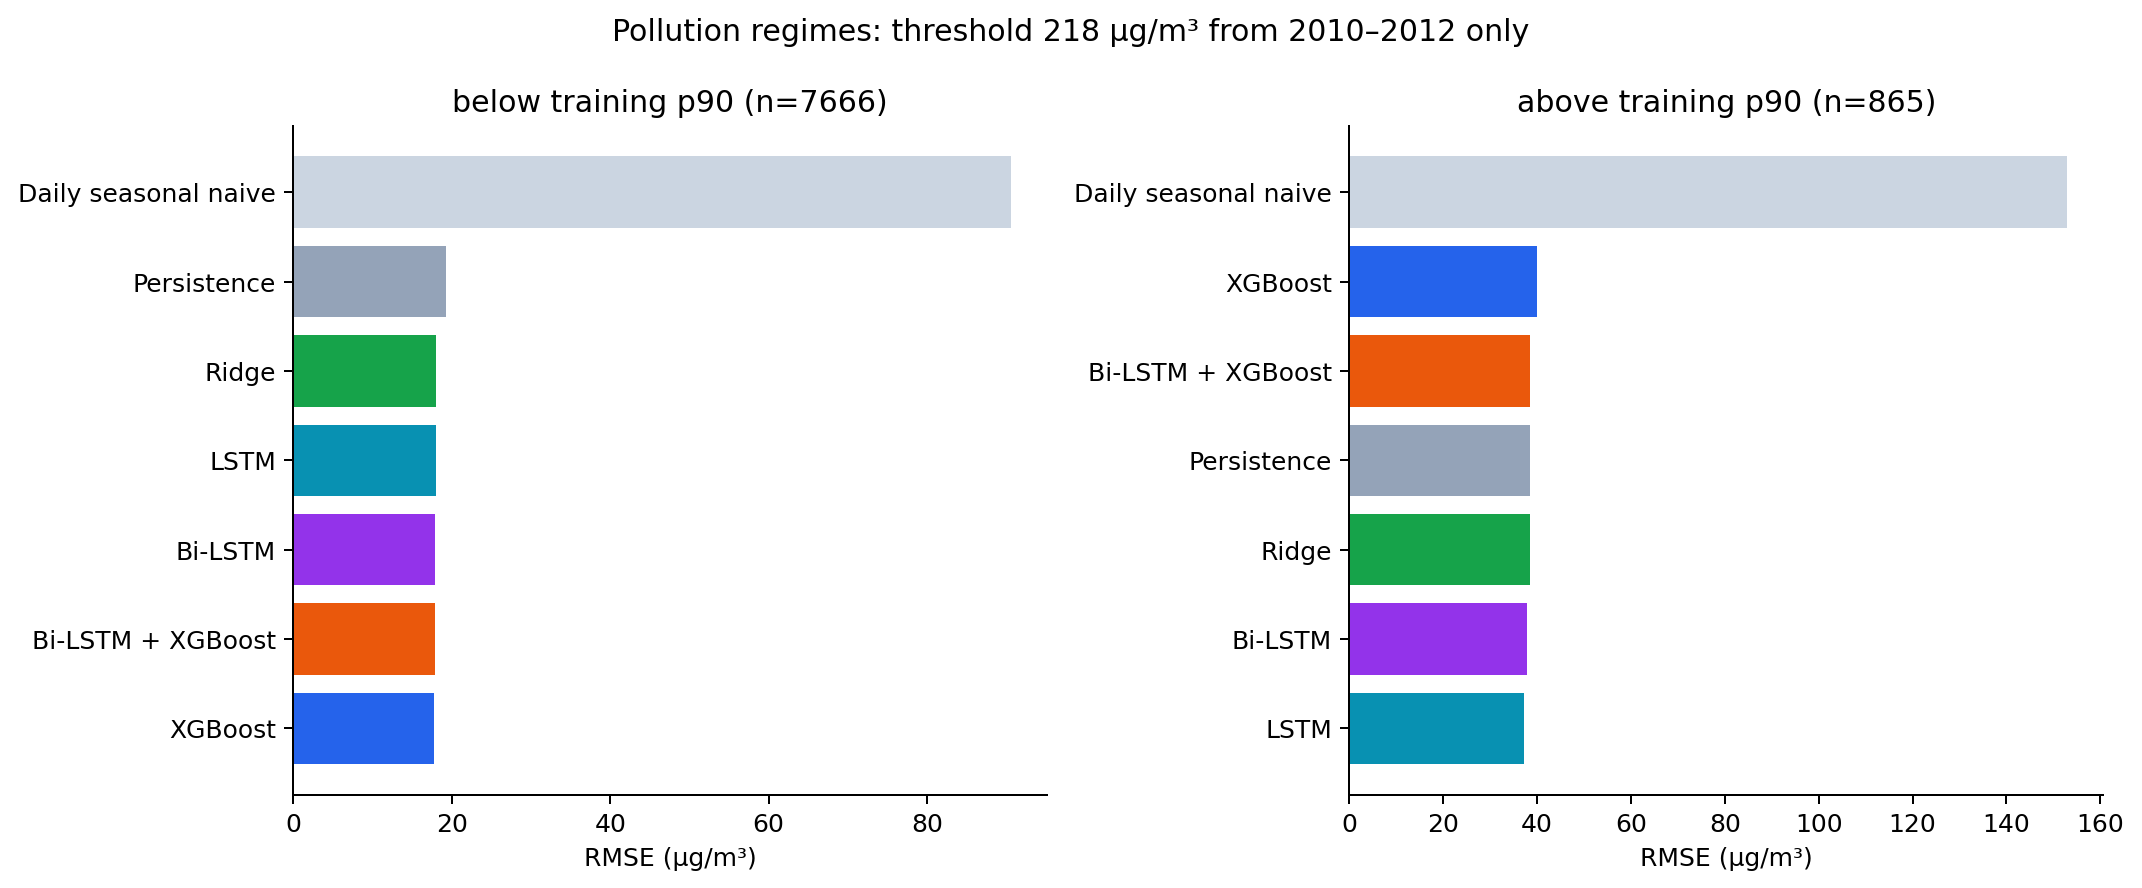

In [6]:
FIGURES = ROOT / 'docs/results/phase2_research'
if RUN_FULL_RESEARCH:
    import subprocess
    FIGURES = RUN / 'report'
    subprocess.check_call([sys.executable, 'scripts/build_phase2_report.py', '--run', str(RUN), '--output', str(FIGURES)])
try:
    from IPython.display import Image as NotebookImage
except ImportError:
    NotebookImage = None
for name in ('model_comparison', 'attention_ablation', 'pollution_regimes'):
    path = FIGURES / (name + '.png')
    if NotebookImage is not None:
        display(NotebookImage(filename=str(path)))
    else:
        print(path)


## Run the saved local models

The sample ends at 2014-12-31 23:00; forecasts refer to the following hour. These are historical examples, not live air quality or a new measured accuracy result.


In [7]:
for name in manifest['models']:
    result = predict_latest(RUN / (name + '.joblib'), DATA)
    assert pd.notna(result['pm25_ug_m3'])
    print(json.dumps(result, indent=2))


{
  "model": "bilstm",
  "origin_time": "2014-12-31 23:00:00",
  "target_time": "2015-01-01 00:00:00",
  "horizon_hours": 1,
  "pm25_ug_m3": 11.78113842010498,
  "latest_pm25_missing": false,
  "source": "uci381_user_supplied"
}
{
  "model": "lstm",
  "origin_time": "2014-12-31 23:00:00",
  "target_time": "2015-01-01 00:00:00",
  "horizon_hours": 1,
  "pm25_ug_m3": 12.197717666625977,
  "latest_pm25_missing": false,
  "source": "uci381_user_supplied"
}
{
  "model": "hybrid",
  "origin_time": "2014-12-31 23:00:00",
  "target_time": "2015-01-01 00:00:00",
  "horizon_hours": 1,
  "pm25_ug_m3": 12.48949247598648,
  "latest_pm25_missing": false,
  "source": "uci381_user_supplied"
}


## Verification and demonstration

Run `pytest -q -W error::DeprecationWarning` for automated checks and `bash scripts/start_frontend.sh` for the local dashboard. The existing hosted classical deployment remains separate.

Dataset: UCI Beijing PM2.5, DOI 10.24432/C5JS49, CC BY 4.0. Methods, measured limitations, references and the original team details are in the Phase 2 report.
